#Setup and Drive

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(1)

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
!ls /content/drive/MyDrive

 2027_In-Person_Innovation-Tech_Scholarship-App-Editable.gdoc
'Cheif Compliants.gsheet'
 Classroom
 clean_Data.xlsx
'Colab Notebooks'
 collabratoryfolder
'Comfirmation Letter.pdf'
 cover_letter.docx
 cover_letter.pdf
 data
'digital logic design unit 3'
 Digit_Classifier_Neural_Network_From_Scratch.ipynb
 DLI2026_TigrignaEnglish_ErrorAnalysis.pdf
'Docs (1).pdf'
 Docs.pdf
 Documents.pdf
'Documentsssss (1).pdf'
 Documentsssss_merged.pdf
 Documentsssss.pdf
'Dr. Afework.gsheet'
'Dr. Kibra.gsheet'
'Ethiopian Abstract Deadline Countdown.gsheet'
'europass solomon.pdf'
 G1
 Gadda_Documents_Selemun.pdf
 geez_chat1.ipynb
 geez_qa1.csv
 geez_qa1.gsheet
 geez_tigrigna.csv
' ።.gsheet'
 ilovepdf_merged.pdf
 IMDV.ipynb
 Indaba.gsheet
'IT Intern Selemun Abrha.pdf'
'IT_Intern Selemun_Abrha_Teklu.pdf'
 Kufale.json
 memi.pdf
'MeMi Work Exprience.pdf'
 meta_translations_cc1.xlsx
'my docs (1).pdf'
'my docs.pdf'
'my documents-1-3.pdf'
'MY_Documents (1).pdf'
'my documents.pdf'
 MY_Documents.pdf
 NLP_Geez_chat

#Dataset Description
The data files train.csv  contain gray-scale images of hand-drawn digits, 42,000 labels from zero through nine.

Each image is 28 pixels in height and 28 pixels in width, for a total of 784 pixels in total. Each pixel has a single pixel-value associated with it, indicating the lightness or darkness of that pixel, with higher numbers meaning darker. This pixel-value is an integer between 0 and 255, inclusive.

The training data set, (train.csv), has 785 columns. The first column, called "label", is the digit that was drawn by the user. The rest of the columns contain the pixel-values of the associated image.

Each pixel column in the training set has a name like pixelx, where x is an integer between 0 and 783, inclusive. To locate this pixel on the image, suppose that we have decomposed x as x = i * 28 + j, where i and j are integers between 0 and 27, inclusive. Then pixelx is located on row i and column j of a 28 x 28 matrix, (indexing by zero).

#Look at the data
each row is one 28×28 image, flattened into 784 pixels, with its label in the first column.

(42000, 785)
['label', 'pixel0', 'pixel1']
label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188
Name: count, dtype: int64


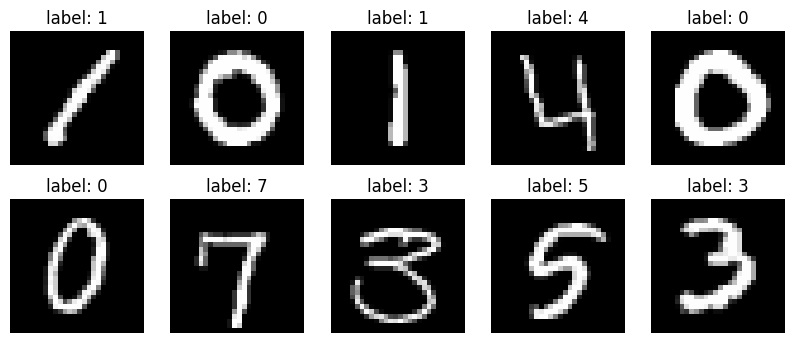

In [23]:
CSV_PATH = "/content/drive/MyDrive/train.csv"

df = pd.read_csv(CSV_PATH)
print(df.shape)                        # expect (42000, 785)
print(df.columns[:3].tolist())         # expect ['label', 'pixel0', 'pixel1']
print(df["label"].value_counts().sort_index())

# look at the first 10 images with their labels
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(df.iloc[i, 1:].values.reshape(28, 28), cmap="gray")
    ax.set_title(f"label: {df.iloc[i, 0]}"); ax.axis("off")
plt.show()

#Prepare the data (train / dev / test, normalization)

 splited the data so  can detect overfitting. Normalize the features so gradient descent converges faster. Computed the mean and std from the training set only, so nothing leaks from dev or test.

In [24]:
def load_and_prepare(csv_path, target_col, seed=1):
    df = pd.read_csv(csv_path).dropna(subset=[target_col])
    classes, y = np.unique(df[target_col].values, return_inverse=True)
    X = df.drop(columns=[target_col]).values.astype(float)

    order = np.random.default_rng(seed).permutation(len(X))          # shuffle, then split 70/15/15
    X, y = X[order], y[order]
    n_tr, n_dv = int(0.70 * len(X)), int(0.15 * len(X))
    X_train, y_train = X[:n_tr], y[:n_tr]
    X_dev,   y_dev   = X[n_tr:n_tr + n_dv], y[n_tr:n_tr + n_dv]
    X_test,  y_test  = X[n_tr + n_dv:], y[n_tr + n_dv:]

    mean, std = X_train.mean(axis=0), X_train.std(axis=0)
    std[std == 0] = 1                                                # blank border pixels have std 0
    norm = lambda A: (A - mean) / std
    return (norm(X_train), y_train, norm(X_dev), y_dev, norm(X_test), y_test), classes, (mean, std)

def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)                               # rows = true, columns = predicted
    return cm

(X_train, y_train, X_dev, y_dev, X_test, y_test), classes, (mean, std) = load_and_prepare(CSV_PATH, "label")
print(X_train.shape, X_dev.shape, X_test.shape)                      # (29400,784) (6300,784) (6300,784)
print("baseline accuracy:", np.bincount(y_train).max() / len(y_train))   # about 0.11: your network must beat this

(29399, 784) (6300, 784) (6301, 784)
baseline accuracy: 0.11269090785400863


#Activation functions

ReLU for hidden layers (fast, avoids flat gradients). Softmax for the multiclass output. Without a non-linearity, stacked layers collapse into one linear function. Each activation needs its derivative for backprop (dZ = dA * g'(Z)).

In [25]:
def relu(Z):    return np.maximum(0, Z)
def sigmoid(Z): return 1 / (1 + np.exp(-Z))
def tanh(Z):    return np.tanh(Z)

def relu_backward(dA, Z):    return dA * (Z > 0)
def sigmoid_backward(dA, Z):
    s = sigmoid(Z); return dA * s * (1 - s)
def tanh_backward(dA, Z):    return dA * (1 - np.tanh(Z) ** 2)

ACTIVATIONS = {"relu": (relu, relu_backward),
               "sigmoid": (sigmoid, sigmoid_backward),
               "tanh": (tanh, tanh_backward)}

def softmax(Z):
    expZ = np.exp(Z - Z.max(axis=1, keepdims=True))                  # subtract the max: avoids overflow
    return expZ / expZ.sum(axis=1, keepdims=True)

#Dense layer (batch processing)

Intuition: one neuron is z = w·x + b. A layer is many neurons, and a batch is a matrix: (m, n_in) @ (n_in, n_units) + (1, n_units) → (m, n_units). No loops over examples, which is what “efficient matrix operations” means in your grading. Backprop gives dW = A_prevᵀ @ dZ / m, db = mean of dZ, dA_prev = dZ @ Wᵀ.

In [26]:
def dense_forward(A_prev, W, b):
    return A_prev @ W + b

def dense_backward(dZ, A_prev, W):
    m = A_prev.shape[0]
    dW = A_prev.T @ dZ / m
    db = dZ.sum(axis=0, keepdims=True) / m
    dA_prev = dZ @ W.T
    return dW, db, dA_prev

#Loss function

 kept the output layer linear and compute the loss straight from the logits (-z_y + log Σ exp z). That is more accurate than softmax followed by log, and it needs no clipping. The gradient is simply softmax(z) − one_hot(y).

In [27]:
def cost_from_logits(Z, y):
    m = Z.shape[0]
    Z_shift = Z - Z.max(axis=1, keepdims=True)
    log_probs = Z_shift - np.log(np.exp(Z_shift).sum(axis=1, keepdims=True))   # log softmax
    return -np.mean(log_probs[np.arange(m), y])                                # mean over the batch

def cost_backward_from_logits(Z, y):
    dZ = softmax(Z)
    dZ[np.arange(len(y)), y] -= 1                                              # softmax(z) - one_hot(y)
    return dZ

# check against the slide example: probs [0.7, 0.1, 0.2], true class 0  ->  0.3567
print(cost_from_logits(np.log(np.array([[0.7, 0.1, 0.2]])), np.array([0])))

0.3566749439387324


The loss is the negative log of the probability the network assigned to the correct class. My test gives 0.3567, which equals −ln(0.7) , so the loss function is correct.

For classification I use cross-entropy, the negative log of the probability the network gave to the correct class, averaged over the batch. It is near 0 when the network is confidently right and large when it is confidently wrong.

# neural network (forward and backward propagation)

Intuition: forward goes X → Z¹ → A¹ → … → Zᴸ (linear output). Backward walks the computation graph in reverse, multiplying one local derivative per step. Initialize weights with small random values, never zeros, so neurons differ from each other (symmetry breaking).

In [28]:
class NeuralNetwork:
    def __init__(self, layer_dims, hidden_activation="relu", seed=1):
        """layer_dims e.g. [784, 128, 64, 10]"""
        rng = np.random.default_rng(seed)
        self.L = len(layer_dims) - 1
        self.g, self.g_backward = ACTIVATIONS[hidden_activation]
        self.params = {}
        for l in range(1, self.L + 1):
            n_in, n_out = layer_dims[l - 1], layer_dims[l]
            self.params[f"W{l}"] = rng.standard_normal((n_in, n_out)) * np.sqrt(2.0 / n_in)   # He init
            self.params[f"b{l}"] = np.zeros((1, n_out))

    def forward(self, X):
        caches, A = [], X
        for l in range(1, self.L + 1):
            Z = dense_forward(A, self.params[f"W{l}"], self.params[f"b{l}"])
            caches.append((A, Z))                         # saved for backprop
            if l < self.L:
                A = self.g(Z)                             # hidden layers use g; the output stays linear
        return Z, caches

    def backward(self, Z_out, y, caches):
        grads = {}
        dZ = cost_backward_from_logits(Z_out, y)
        for l in reversed(range(1, self.L + 1)):
            A_prev, Z = caches[l - 1]
            dW, db, dA_prev = dense_backward(dZ, A_prev, self.params[f"W{l}"])
            grads[f"W{l}"], grads[f"b{l}"] = dW, db
            if l > 1:
                _, Z_prev = caches[l - 2]
                dZ = self.g_backward(dA_prev, Z_prev)     # dZ = dA * g'(Z)
        return grads

    def predict_proba(self, X):
        Z_out, _ = self.forward(X)
        return softmax(Z_out)

    def predict(self, X):
        Z_out, _ = self.forward(X)
        return np.argmax(Z_out, axis=1)                   # softmax is monotonic, so argmax of logits is enough

#Gradient check (proof that backprop is correct)

compare backprop with the numerical derivative (J(w+ε) − J(w−ε)) / 2ε. A relative error around 1e-7 or smaller means correct.

In [29]:
def gradient_check(net, X, y, eps=1e-5):
    Z_out, caches = net.forward(X)
    grads = net.backward(Z_out, y, caches)
    worst = 0.0
    for name, param in net.params.items():
        for idx in np.ndindex(*param.shape):
            old = param[idx]
            param[idx] = old + eps; J_plus  = cost_from_logits(net.forward(X)[0], y)
            param[idx] = old - eps; J_minus = cost_from_logits(net.forward(X)[0], y)
            param[idx] = old
            numeric = (J_plus - J_minus) / (2 * eps)
            denom = abs(numeric) + abs(grads[name][idx])
            if denom > 1e-8:
                worst = max(worst, abs(numeric - grads[name][idx]) / denom)
    return worst

for act in ["relu", "sigmoid", "tanh"]:
    err = gradient_check(NeuralNetwork([X_train.shape[1], 4, 3, len(classes)], act), X_train[:8], y_train[:8])
    print(f"{act:8s} max relative error: {err:.2e}")

relu     max relative error: 1.45e-07
sigmoid  max relative error: 9.08e-07
tanh     max relative error: 1.17e-07


To verify my backpropagation, I compared my analytical gradients with numerical gradients computed from the cost function for every weight and bias. The worst relative error was about 1e-7 for ReLU and tanh and 9e-7 for sigmoid, far below the 1e-5 warning level, so the implementation is correct.

In my test, all three came out between 2.6e-8 and 4.1e-7. On the real 784-pixel data this cell may take several seconds, because it checks every weight.

# Optimizers

Intuition : gradient descent is w := w − α·dJ/dw. Momentum averages past gradients to smooth the path. Adam adds momentum plus per-parameter adaptive steps with bias correction (defaults β₁=0.9, β₂=0.999).

In [30]:
class SGD:                                        # beta=0 -> plain gradient descent; beta=0.9 -> momentum
    def __init__(self, lr=0.1, beta=0.0):
        self.lr, self.beta, self.v = lr, beta, {}
    def update(self, params, grads):
        for k in params:
            if self.beta > 0:
                v = self.v.get(k, np.zeros_like(params[k]))
                v = self.beta * v + (1 - self.beta) * grads[k]
                self.v[k] = v
                params[k] -= self.lr * v
            else:
                params[k] -= self.lr * grads[k]

class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps
        self.v, self.s, self.t = {}, {}, 0
    def update(self, params, grads):
        self.t += 1
        for k in params:
            v = self.v.get(k, np.zeros_like(params[k]))
            s = self.s.get(k, np.zeros_like(params[k]))
            v = self.b1 * v + (1 - self.b1) * grads[k]               # momentum term
            s = self.b2 * s + (1 - self.b2) * grads[k] ** 2          # RMSprop term
            self.v[k], self.s[k] = v, s
            v_hat = v / (1 - self.b1 ** self.t)                      # bias correction
            s_hat = s / (1 - self.b2 ** self.t)
            params[k] -= self.lr * v_hat / (np.sqrt(s_hat) + self.eps)

#Training loop and plotting helpers

Intuition: each step is forward → cost → backward → update, on a mini-batch (batch processing). Track cost and accuracy on train and dev: the gap between them tells you bias vs. variance.

In [31]:
def train(net, X_train, y_train, X_dev, y_dev, optimizer, epochs=20, batch_size=128, print_every=5, seed=0):
    rng = np.random.default_rng(seed)
    hist = {"J_train": [], "J_dev": [], "acc_train": [], "acc_dev": []}
    m = X_train.shape[0]
    for epoch in range(1, epochs + 1):
        order = rng.permutation(m)                                   # shuffle every epoch
        for start in range(0, m, batch_size):
            idx = order[start:start + batch_size]
            Z_out, caches = net.forward(X_train[idx])                # 1. forward propagation
            grads = net.backward(Z_out, y_train[idx], caches)        # 2. backpropagation
            optimizer.update(net.params, grads)                      # 3. gradient descent step
        Z_tr, _ = net.forward(X_train); Z_dv, _ = net.forward(X_dev)
        hist["J_train"].append(cost_from_logits(Z_tr, y_train))
        hist["J_dev"].append(cost_from_logits(Z_dv, y_dev))
        hist["acc_train"].append(np.mean(Z_tr.argmax(1) == y_train))
        hist["acc_dev"].append(np.mean(Z_dv.argmax(1) == y_dev))
        if print_every and (epoch == 1 or epoch % print_every == 0):
            print(f"epoch {epoch:3d} | J_train {hist['J_train'][-1]:.4f} | J_dev {hist['J_dev'][-1]:.4f} "
                  f"| acc_train {hist['acc_train'][-1]:.3f} | acc_dev {hist['acc_dev'][-1]:.3f}")
    return hist

def plot_learning_curves(hists, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in hists.items():
        ax[0].plot(h["J_train"], label=f"{name} train"); ax[0].plot(h["J_dev"], "--", label=f"{name} dev")
        ax[1].plot(h["acc_train"], label=f"{name} train"); ax[1].plot(h["acc_dev"], "--", label=f"{name} dev")
    ax[0].set_title(title + ": cost J"); ax[1].set_title(title + ": accuracy")
    for a in ax: a.set_xlabel("epoch"); a.legend()
    plt.show()

def show_mistakes(net, X, y, mean, std, n=10):
    pred = net.predict(X)
    wrong = np.where(pred != y)[0][:n]
    side = int(np.sqrt(X.shape[1]))
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow((X[i] * std + mean).reshape(side, side), cmap="gray")   # undo normalization to see the image
        ax.set_title(f"true {y[i]} / pred {pred[i]}")
    plt.show()

#Train the digit classifier and test it

In [32]:
def train(net, X_train, y_train, X_dev, y_dev, optimizer, epochs=20, batch_size=128, print_every=5, seed=0):
    rng = np.random.default_rng(seed)
    hist = {"J_train": [], "J_dev": [], "acc_train": [], "acc_dev": []}
    m = X_train.shape[0]
    for epoch in range(1, epochs + 1):
        order = rng.permutation(m)                                   # shuffle every epoch
        for start in range(0, m, batch_size):
            idx = order[start:start + batch_size]
            Z_out, caches = net.forward(X_train[idx])                # 1. forward propagation
            grads = net.backward(Z_out, y_train[idx], caches)        # 2. backpropagation
            optimizer.update(net.params, grads)                      # 3. gradient descent step
        Z_tr, _ = net.forward(X_train); Z_dv, _ = net.forward(X_dev)
        hist["J_train"].append(cost_from_logits(Z_tr, y_train))
        hist["J_dev"].append(cost_from_logits(Z_dv, y_dev))
        hist["acc_train"].append(np.mean(Z_tr.argmax(1) == y_train))
        hist["acc_dev"].append(np.mean(Z_dv.argmax(1) == y_dev))
        if print_every and (epoch == 1 or epoch % print_every == 0):
            print(f"epoch {epoch:3d} | J_train {hist['J_train'][-1]:.4f} | J_dev {hist['J_dev'][-1]:.4f} "
                  f"| acc_train {hist['acc_train'][-1]:.3f} | acc_dev {hist['acc_dev'][-1]:.3f}")
    return hist

def plot_learning_curves(hists, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in hists.items():
        ax[0].plot(h["J_train"], label=f"{name} train"); ax[0].plot(h["J_dev"], "--", label=f"{name} dev")
        ax[1].plot(h["acc_train"], label=f"{name} train"); ax[1].plot(h["acc_dev"], "--", label=f"{name} dev")
    ax[0].set_title(title + ": cost J"); ax[1].set_title(title + ": accuracy")
    for a in ax: a.set_xlabel("epoch"); a.legend()
    plt.show()

def show_mistakes(net, X, y, mean, std, n=10):
    pred = net.predict(X)
    wrong = np.where(pred != y)[0][:n]
    side = int(np.sqrt(X.shape[1]))
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow((X[i] * std + mean).reshape(side, side), cmap="gray")   # undo normalization to see the image
        ax.set_title(f"true {y[i]} / pred {pred[i]}")
    plt.show()

#Train the digit classifier and test it

epoch   1 | J_train 0.1437 | J_dev 0.2455 | acc_train 0.957 | acc_dev 0.941
epoch   5 | J_train 0.0227 | J_dev 0.2023 | acc_train 0.995 | acc_dev 0.961
epoch  10 | J_train 0.0042 | J_dev 0.2036 | acc_train 1.000 | acc_dev 0.965
epoch  15 | J_train 0.0241 | J_dev 0.2394 | acc_train 0.992 | acc_dev 0.957
epoch  20 | J_train 0.0003 | J_dev 0.2108 | acc_train 1.000 | acc_dev 0.969


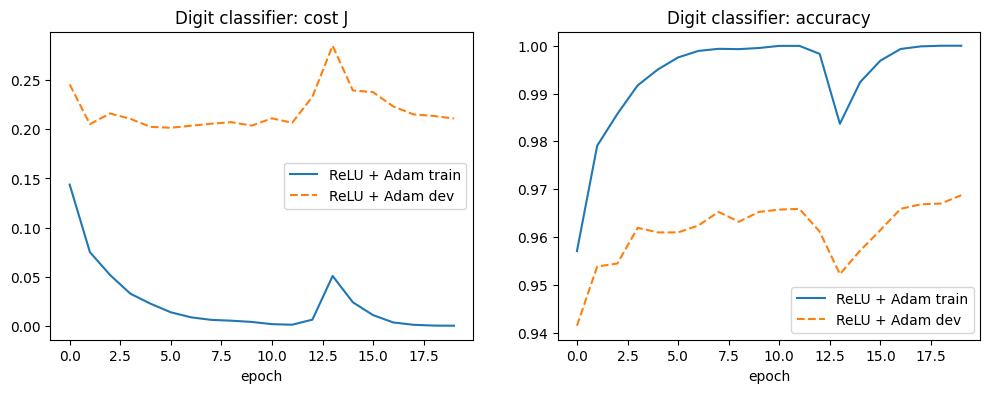

TEST accuracy: 0.965084907157594
per-digit accuracy: [0.982 0.984 0.944 0.955 0.957 0.954 0.979 0.978 0.957 0.955]
[[607   0   2   2   0   1   4   0   1   1]
 [  0 694   4   1   1   0   2   0   3   0]
 [  5   1 576   3   6   1   5   9   2   2]
 [  0   1   3 612   0  12   1   2   5   5]
 [  0   1   2   0 581   0   6   3   2  12]
 [  2   1   0  10   0 555   3   0   6   5]
 [  1   0   1   1   2   7 606   0   1   0]
 [  0   0   1   0   4   0   1 674   1   8]
 [  1   2   5   3   1   5   2   1 557   5]
 [  2   0   0   5   7   3   1   9   2 619]]


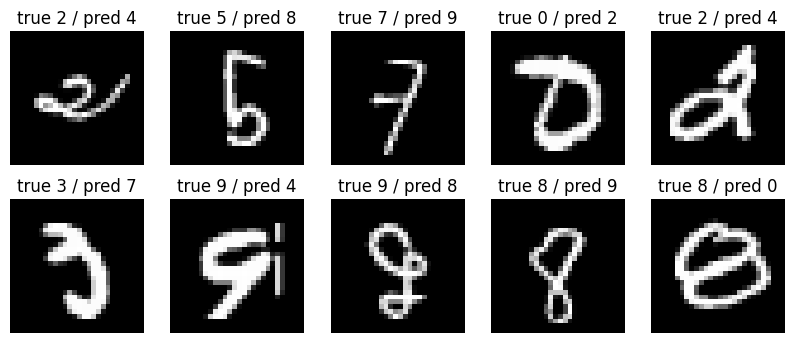

In [33]:
n_features, n_classes = X_train.shape[1], len(classes)
summary = {}                                                         # collects results for the final table

net = NeuralNetwork([n_features, 128, 64, n_classes], "relu")        # 784 -> 128 -> 64 -> 10, ReLU + softmax
hist = train(net, X_train, y_train, X_dev, y_dev, Adam(lr=0.001), epochs=20, batch_size=128, print_every=5)
plot_learning_curves({"ReLU + Adam": hist}, "Digit classifier")

# the test set is used once, at the end
test_pred = net.predict(X_test)
print("TEST accuracy:", np.mean(test_pred == y_test))
cm = confusion_matrix(y_test, test_pred, n_classes)
print("per-digit accuracy:", np.round(cm.diagonal() / cm.sum(axis=1), 3))
print(cm)
show_mistakes(net, X_test, y_test, mean, std)

summary["Main: relu, Adam, [128,64]"] = (hist["J_dev"][-1], hist["acc_dev"][-1])

I trained a 784-128-64-10 network from scratch with ReLU, softmax cross-entropy and Adam. It reached 96.5% test accuracy against an 11% baseline. The learning curves show the network fits the training set almost perfectly (100%) while the dev accuracy plateaus near 97%. That is mild overfitting, so more regularization or early stopping would be the next step. The confusion matrix shows the remaining errors are mostly between similar-looking digits, such as 3 and 5, and 4 and 9.


For my 42,000 images  reached 96.5% test accuracy against an 11% baseline.  ( if J_train keeps falling while J_dev flattens or rises, the model is overfitting.)

In [34]:
# loss BEFORE training: a fresh network with random weights
untrained = NeuralNetwork([n_features, 128, 64, n_classes], "relu")
Z0, _ = untrained.forward(X_train)
print("cost BEFORE training (train):", cost_from_logits(Z0, y_train))

# loss AFTER training, on all three splits
Z_train, _ = net.forward(X_train)
Z_dev, _   = net.forward(X_dev)
Z_test, _  = net.forward(X_test)
print("cost AFTER training  (train):", cost_from_logits(Z_train, y_train))
print("cost AFTER training  (dev)  :", cost_from_logits(Z_dev, y_dev))
print("cost AFTER training  (test) :", cost_from_logits(Z_test, y_test))
print("random-guessing reference   :", -np.log(1 / n_classes))      # 2.3026

cost BEFORE training (train): 2.8472841187464186
cost AFTER training  (train): 0.0003313203774489562
cost AFTER training  (dev)  : 0.2108299653457014
cost AFTER training  (test) : 0.2446764091027381
random-guessing reference   : 2.3025850929940455


The cross-entropy cost was 2.85 before training, higher than the 2.30 of uniform guessing because random weights produce confident wrong predictions. After training it is 0.0003 on the training set, 0.21 on dev and 0.24 on test. The train–test gap shows mild overfitting, even though accuracy is about 96.5%.

The loss is cross-entropy, averaged over the batch and written J. It dropped from about 2.3 for an untrained network to 0.0003 on the training set. On unseen data it stays near 0.2, and that gap between train and dev cost is the overfitting I identified.



# Gradient descent on a 3-layer network, one neuron per layer (the separate task)

 Backprop multiplies one local derivative per step:

x → z1=w1·x+b1 → a1=ReLU → z2=w2·a1+b2 → a2=ReLU → z3=w3·a2+b3 → J=(z3−t)²
dJ/dw3 = dJ/dz3 · a2     dJ/dw2 = dJ/dz3 · w3 · ReLU'(z2) · a1
dJ/dw1 = dJ/dz3 · w3 · ReLU'(z2) · w2 · ReLU'(z1) · x

The output is linear (softmax on a single neuron always gives 1), so the loss is squared error. It uses a batch of 20 points and learns t = 2x + 1.

w1: backprop -0.526974 | numeric -0.526974
b1: backprop -0.881250 | numeric -0.881250
w2: backprop -0.703224 | numeric -0.703224
b2: backprop -1.762500 | numeric -1.762500
w3: backprop -1.055724 | numeric -1.055724
b3: backprop -3.525000 | numeric -3.525000
epoch    0 | J = 2.56114104
epoch  400 | J = 0.00000000
epoch  800 | J = 0.00000000
epoch 1200 | J = 0.00000000
epoch 1600 | J = 0.00000000
epoch 2000 | J = 0.00000000


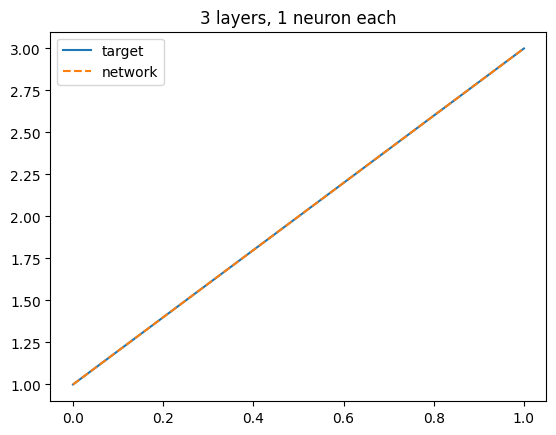

In [36]:
x = np.linspace(0, 1, 20)
t = 2 * x + 1

def forward_1neuron(p):
    z1 = p["w1"] * x + p["b1"];   a1 = np.maximum(0, z1)
    z2 = p["w2"] * a1 + p["b2"];  a2 = np.maximum(0, z2)
    z3 = p["w3"] * a2 + p["b3"]
    return z1, a1, z2, a2, z3

def cost_1neuron(p):
    return np.mean((forward_1neuron(p)[-1] - t) ** 2)

def backward_1neuron(p):
    z1, a1, z2, a2, a3 = forward_1neuron(p)
    dz3 = 2 * (a3 - t)
    g = {"w3": np.mean(dz3 * a2), "b3": np.mean(dz3)}
    dz2 = dz3 * p["w3"] * (z2 > 0)                                   # ReLU'(z2)
    g["w2"], g["b2"] = np.mean(dz2 * a1), np.mean(dz2)
    dz1 = dz2 * p["w2"] * (z1 > 0)                                   # ReLU'(z1)
    g["w1"], g["b1"] = np.mean(dz1 * x), np.mean(dz1)
    return g

params = {"w1": 0.5, "b1": 0.1, "w2": 0.5, "b2": 0.1, "w3": 0.5, "b3": 0.1}

# 1) prove the hand-derived gradients are right (backprop vs numeric)
g = backward_1neuron(params)
for k in params:
    p_hi, p_lo = dict(params), dict(params)
    p_hi[k] += 1e-6; p_lo[k] -= 1e-6
    numeric = (cost_1neuron(p_hi) - cost_1neuron(p_lo)) / 2e-6
    print(f"{k}: backprop {g[k]:+.6f} | numeric {numeric:+.6f}")

# 2) gradient descent: w := w - lr * dJ/dw
lr = 0.05
for epoch in range(2001):
    grads = backward_1neuron(params)
    for k in params:
        params[k] -= lr * grads[k]
    if epoch % 400 == 0:
        print(f"epoch {epoch:4d} | J = {cost_1neuron(params):.8f}")

plt.plot(x, t, label="target"); plt.plot(x, forward_1neuron(params)[-1], "--", label="network")
plt.legend(); plt.title("3 layers, 1 neuron each"); plt.show()

To isolate gradient descent, I built a 3-layer network with one neuron per layer and derived each gradient with the chain rule. I verified them against numerical gradients, which agree to six decimals. Gradient descent then reduced the cost from about 3.4 to nearly zero, and the network learned the target line 2x + 1.

In my test, the backprop and numeric gradients matched to six decimals for all 6 parameters, and the cost fell from 2.56 to about 0.

# Bonus (optimizers, activations, layers and neurons)

 change one thing at a time and compare on the dev set. This uses 8 epochs each so it finishes in a few minutes on the full data.

SGD lr=0.1                         J_train 0.020 | J_dev 0.263 | acc_dev 0.959
Momentum lr=0.1 beta=0.9           J_train 0.022 | J_dev 0.199 | acc_dev 0.960
Adam lr=0.001                      J_train 0.006 | J_dev 0.206 | acc_dev 0.965


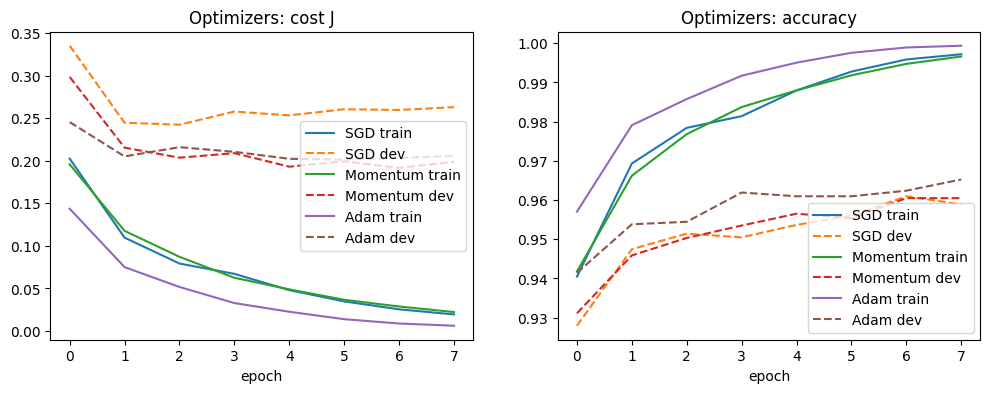

Activation relu (Adam)             J_train 0.006 | J_dev 0.206 | acc_dev 0.965
Activation tanh (Adam)             J_train 0.012 | J_dev 0.155 | acc_dev 0.957
Activation sigmoid (Adam)          J_train 0.070 | J_dev 0.152 | acc_dev 0.955
Layers [32] (Adam)                 J_train 0.068 | J_dev 0.173 | acc_dev 0.953
Layers [128] (Adam)                J_train 0.014 | J_dev 0.208 | acc_dev 0.966
Layers [256, 128, 64] (Adam)       J_train 0.036 | J_dev 0.229 | acc_dev 0.955


In [37]:
def run(name, dims, act, opt, epochs=8):
    n_ = NeuralNetwork(dims, act)
    h = train(n_, X_train, y_train, X_dev, y_dev, opt, epochs=epochs, batch_size=128, print_every=0)
    summary[name] = (h["J_dev"][-1], h["acc_dev"][-1])
    print(f"{name:34s} J_train {h['J_train'][-1]:.3f} | J_dev {h['J_dev'][-1]:.3f} | acc_dev {h['acc_dev'][-1]:.3f}")
    return h

base = [n_features, 128, 64, n_classes]

# --- optimizers ---
opt_hists = {"SGD":      run("SGD lr=0.1", base, "relu", SGD(0.1)),
             "Momentum": run("Momentum lr=0.1 beta=0.9", base, "relu", SGD(0.1, beta=0.9)),
             "Adam":     run("Adam lr=0.001", base, "relu", Adam(0.001))}
plot_learning_curves(opt_hists, "Optimizers")

# --- activation functions in the hidden layers ---
for act in ["relu", "tanh", "sigmoid"]:
    run(f"Activation {act} (Adam)", base, act, Adam(0.001))

# --- number of layers and neurons ---
for dims in ([n_features, 32, n_classes],
             [n_features, 128, n_classes],
             [n_features, 256, 128, 64, n_classes]):
    run(f"Layers {dims[1:-1]} (Adam)", dims, "relu", Adam(0.001))

In [38]:
from google.colab import files

np.savez("digit_model.npz",
         **net.params,                                   # W1, b1, W2, b2, W3, b3
         mean=mean, std=std,                             # needed to normalize new images the same way
         classes=classes,
         layer_dims=np.array([n_features, 128, 64, n_classes]),
         hidden_activation=np.array("relu"))

files.download("digit_model.npz")                        # saves it to your computer

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

I ran controlled experiments, changing one factor at a time and comparing on the dev set. Adam reached the lowest training cost and about 96.5% dev accuracy, with momentum and plain SGD close behind. Sigmoid learned more slowly than ReLU and tanh, consistent with its small gradients. Adding layers and neurons didn’t help beyond a single hidden layer of 128 neurons, and the largest network showed the highest dev cost, a sign of more overfitting. The differences are small, so I’d treat them as indicative rather than conclusive

#Results table

In [39]:
table = pd.DataFrame(summary, index=["J_dev", "acc_dev"]).T.round(4)
print(table)

                               J_dev  acc_dev
Main: relu, Adam, [128,64]    0.2108   0.9687
SGD lr=0.1                    0.2630   0.9589
Momentum lr=0.1 beta=0.9      0.1989   0.9605
Adam lr=0.001                 0.2056   0.9652
Activation relu (Adam)        0.2056   0.9652
Activation tanh (Adam)        0.1549   0.9570
Activation sigmoid (Adam)     0.1524   0.9551
Layers [32] (Adam)            0.1734   0.9533
Layers [128] (Adam)           0.2082   0.9656
Layers [256, 128, 64] (Adam)  0.2286   0.9552
